# SoLEXS + HEL1OS spectra (Aditya-L1)

| | |
|---|---|
| **Author** | Prakhar Singh |
| **Affiliation** | Aryabhatta Research Institute of Observational Sciences (ARIES), Nainital |
| **Email** | prakhar.aries@gmail.com |
| **Date** | 19 November 2026 |

---

Makes **SoLEXS and HEL1OS spectra over the same time bins**, ready for XSPEC, with the instrument teams' tools.
Example: solar flare of 15 June 2025.

| Instrument | Input (level 1) | Tool |
|---|---|---|
| SoLEXS (SDD2) | spectra (1 s) + good-time intervals | `solexs_tools` (SoLEXS team) |
| HEL1OS (CdTe1 or CdTe2) | event list `evt.fits` | `Evt-To-Mutiple-TypeI_V1.py` (HEL1OS team) |

The spectra are then grouped with `grppha` (HEASoft), and the HEL1OS pre-flare spectrum is linked as background.

**Output** (`outputs/spectra/<DAY>/`): one SoLEXS and one HEL1OS spectrum per bin (`*_grp.pi`, `*_grp.fits`), the
pre-flare spectra, and `spectra_list.csv` (one line per bin).

## 1. Settings
Times are UTC on `DAY`.

| Setting | Meaning |
|---|---|
| `T_START`, `T_STOP`, `BIN_LENGTH` | time interval and bin length (s) |
| `BKG` | pre-flare window |
| `HLS_DETECTOR` | `'CDTE1'` or `'CDTE2'` |
| `GROUP_MIN` | minimum counts per group (`None` = no grouping) |
| `HLS_EMIN`, `HLS_EMAX` | HEL1OS energy range (keV); SoLEXS uses 2.8–15 keV (set by `solexs_tools`) |

In [1]:
import io
import os
import re
import sys
import zipfile
import contextlib
import csv
import shutil
import subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from astropy.io import fits
from solexs_tools.genspec import solexs_genmultispec, solexs_genspec
%matplotlib inline

ROOT = Path.cwd().resolve().parent    # the repository folder (this notebook is in ROOT/notebooks/)
DATA = ROOT / 'data'                  # the level-1 zip files; unpacked here by this cell

# ---- input data (one day)
DAY     = '2025-06-15'
SLX_PI  = DATA / 'AL1_SLX_L1_20250615_v1.0/SDD2/AL1_SOLEXS_20250615_SDD2_L1.pi.gz'
SLX_GTI = DATA / 'AL1_SLX_L1_20250615_v1.0/SDD2/AL1_SOLEXS_20250615_SDD2_L1.gti.gz'
HLS_EVT = DATA / '2025/06/15/HLS_20250615_121027_42565sec_lev1_V111/events/evt.fits'

# ---- calibration and tools (all in this repository)
os.environ['SOLEXS_CALDB'] = str(ROOT / 'resources/solexs_caldb')     # SoLEXS CALDB, read by solexs_tools
HLS_TOOL = ROOT / 'codes/hel1os_tools/Evt-To-Mutiple-TypeI_V1.py'      # HEL1OS team tool
HLS_RMF  = ROOT / 'resources/hel1os_responses/hel1os_cdte_srf_v04.fits'
HLS_ARF  = ROOT / 'resources/hel1os_responses/hel1os_cdte_arf_v03.fits'

# ---- time bins and pre-flare window
T_START, T_STOP = '17:50:00', '18:10:00'
BIN_LENGTH = 20                                   # s
BKG = ('17:40:00', '17:45:00')

# ---- spectra
HLS_DETECTOR = 'CDTE1'                            # 'CDTE1' or 'CDTE2'
GROUP_MIN = 20                                    # min. counts per group (None = no grouping)
HLS_EMIN, HLS_EMAX = 10.0, 50.0                   # keV, HEL1OS channels kept

OUT = ROOT / 'outputs' / 'spectra' / DAY          # output folder
OUT.mkdir(parents=True, exist_ok=True)

# unpack the level-1 data (only the first time)
for z in sorted(DATA.glob('*.zip')):
    with zipfile.ZipFile(z) as f:
        if not (DATA / f.namelist()[0]).exists():
            print('unpacking', z.name)
            f.extractall(DATA)

# check that every input is in place
for f in (SLX_PI, SLX_GTI, HLS_EVT, HLS_TOOL, HLS_RMF, HLS_ARF):
    assert f.exists(), f'not found: {f}  (see README)'
assert shutil.which('grppha'), 'grppha not found: initialise HEASoft (see README)'

def unix(hms):
    # 'HH:MM:SS' on DAY  ->  seconds since 1970-01-01
    return (np.datetime64(f'{DAY}T{hms}') - np.datetime64('1970-01-01T00:00:00')) / np.timedelta64(1, 's')

def tag(t1, t2):
    # '17:58:40', '17:59:00'  ->  '175840_175900' (the time stamp both tools put in their file names)
    return t1.replace(':', '') + '_' + t2.replace(':', '')

n_bins = int(np.ceil((unix(T_STOP) - unix(T_START)) / BIN_LENGTH))
print(f'{n_bins} bins of {BIN_LENGTH} s: {T_START} - {T_STOP}')
print('pre-flare:', BKG, f'({unix(BKG[1]) - unix(BKG[0]):.0f} s)')

unpacking AL1_SLX_L1_20250615_v1.0.zip
unpacking HLS_20250615_121027_42565sec_lev1_V111.zip


60 bins of 20 s: 17:50:00 - 18:10:00
pre-flare: ('17:40:00', '17:45:00') (300 s)


## 2. Light curves
Count rates from the level-1 files, to check the time bins (thin lines) and the pre-flare window (gray).

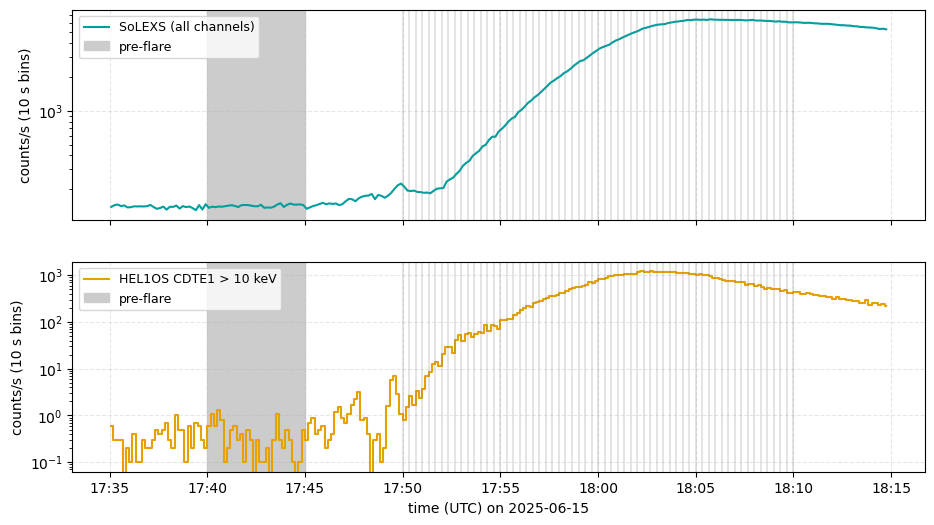

In [2]:
def to_datetime(t):
    return np.datetime64('1970-01-01') + (np.asarray(t) * 1e3).astype('timedelta64[ms]')

STEP = 10                                                    # s, light-curve resolution
t_edges = np.arange(min(unix(BKG[0]), unix(T_START)) - 300, unix(T_STOP) + 300, STEP)
t_mid = to_datetime(t_edges[:-1] + STEP / 2)

# SoLEXS: total counts per 1 s row, inside the good-time intervals
with fits.open(SLX_PI) as h:
    slx_t = np.array(h[1].data['TSTART'], float)
    slx_n = np.nansum(h[1].data['COUNTS'], axis=1)
    slx_x = np.array(h[1].data['EXPOSURE'], float)
gti = fits.getdata(SLX_GTI, 1)
ok = np.zeros(len(slx_t), bool)
for a, b in zip(gti['START'], gti['STOP']):
    ok |= (slx_t >= a) & (slx_t <= b)
n = np.histogram(slx_t[ok], t_edges, weights=slx_n[ok])[0]
x = np.histogram(slx_t[ok], t_edges, weights=slx_x[ok])[0]
slx_rate = np.where(x > 0, n / np.maximum(x, 1e-9), np.nan)

# HEL1OS: events above HLS_EMIN
with fits.open(HLS_EVT, memmap=True) as h:
    d = h[f'{HLS_DETECTOR}-EVENTS'].data
    hls_t = (np.array(d['mjd'], float) - 40587.0) * 86400.0  # MJD -> seconds since 1970
    hls_e = np.array(d['ener'], float)
hls_rate = np.histogram(hls_t[hls_e >= HLS_EMIN], t_edges)[0] / STEP

fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axs[0].plot(t_mid, slx_rate, color='#009e9e', label='SoLEXS (all channels)')
axs[1].step(t_mid, hls_rate, where='mid', color='#e6a100', label=f'HEL1OS {HLS_DETECTOR} > {HLS_EMIN:g} keV')
bin_edges = unix(T_START) + BIN_LENGTH * np.arange(n_bins + 1)
for ax in axs:
    ax.axvspan(to_datetime(unix(BKG[0])), to_datetime(unix(BKG[1])), color='0.8', label='pre-flare')
    for e in bin_edges:
        ax.axvline(to_datetime(min(e, unix(T_STOP))), color='0.5', lw=0.3)
    ax.set_yscale('log')
    ax.set_ylabel(f'counts/s ({STEP} s bins)')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(ls='--', alpha=0.3)
axs[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
axs[1].set_xlabel(f'time (UTC) on {DAY}')
plt.show()

## 3. SoLEXS spectra (`solexs_tools`)
* `solexs_genmultispec`: one spectrum per bin (sum of the 1 s spectra inside the good-time intervals)
* `solexs_genspec`: the pre-flare spectrum (`solexs_bkg.pi`)

Responses (RMF, ARF) are taken from the SoLEXS CALDB and written into each file.

In [3]:
log = io.StringIO()
with contextlib.redirect_stdout(log):           # the tools print one message per file; keep them in `log`
    solexs_genmultispec(str(SLX_PI), f'{DAY}T{T_START}', f'{DAY}T{T_STOP}', BIN_LENGTH, str(SLX_GTI),
                        output_dir=str(OUT))
    slx_bkg = solexs_genspec(str(SLX_PI), f'{DAY}T{BKG[0]}', f'{DAY}T{BKG[1]}', str(SLX_GTI),
                             outfile=str(OUT / 'solexs_bkg'))

made = sorted(OUT.glob(f'{SLX_PI.name.split(".")[0]}_??????_??????.pi'))
print(f'{len(made)} SoLEXS spectra, e.g. {made[0].name}')
print('pre-flare:', Path(slx_bkg).name)
print('responses:', fits.getval(made[0], 'RESPFILE', 1).split('/')[-1], '+', fits.getval(made[0], 'ANCRFILE', 1).split('/')[-1])

60 SoLEXS spectra, e.g. AL1_SOLEXS_20250615_SDD2_L1_175000_175020.pi
pre-flare: solexs_bkg.pi
responses: solexs_gaussian_SDD2_v1.rmf + solexs_arf_SDD2_v1.arf


## 4. HEL1OS spectra (HEL1OS team tool)
`Evt-To-Mutiple-TypeI_V1.py` asks for the date, start, end and bin length; the notebook types these answers for it.
It runs twice: for the time bins and for the pre-flare window. Exposure = bin length.

In [4]:
# the tool needs evt.fits and the responses in the folder where it runs
evt_link = OUT / 'evt.fits'
if evt_link.is_symlink():
    evt_link.unlink()
evt_link.symlink_to(HLS_EVT)
for f in (HLS_RMF, HLS_ARF):
    shutil.copy(f, OUT)

def run_hel1os_tool(t1, t2, length):
    # answers to the tool's questions: date (yyyymmdd), start (hhmmss), end (hhmmss), bin length (s)
    answers = f"{DAY.replace('-', '')}\n{t1.replace(':', '')}\n{t2.replace(':', '')}\n{int(length)}\n"
    r = subprocess.run([sys.executable, str(HLS_TOOL), '--mode', HLS_DETECTOR], input=answers, text=True,
                       cwd=OUT, capture_output=True, env={**os.environ, 'MPLBACKEND': 'Agg'})
    if r.returncode != 0:
        raise RuntimeError(r.stderr)
    return re.findall(r'Generated (\S+)', r.stdout)            # names of the files the tool wrote

made = run_hel1os_tool(T_START, T_STOP, BIN_LENGTH)
print(f'{len(made)} HEL1OS spectra, e.g. {made[0]}')

hls_bkg = run_hel1os_tool(BKG[0], BKG[1], unix(BKG[1]) - unix(BKG[0]))[0]
print('pre-flare:', hls_bkg)

60 HEL1OS spectra, e.g. CDTE1_typeI_spectra_175000_175020.fits


pre-flare: CDTE1_typeI_spectra_174000_174500.fits


## 5. Grouping and background (`grppha`)
* **SoLEXS:** `group min GROUP_MIN`
* **HEL1OS:** channels outside `HLS_EMIN`–`HLS_EMAX` flagged bad, `group min GROUP_MIN`, pre-flare spectrum linked as
  `BACKFILE`

The SoLEXS pre-flare spectrum is not subtracted: it is meant to be modelled (as in notebook 2).

In [5]:
def grppha(infile, outfile, commands):
    commands = commands + ([f'group min {GROUP_MIN}'] if GROUP_MIN else [])
    r = subprocess.run(['grppha', f'infile={infile}', f'outfile={outfile}', 'clobber=yes', 'chatter=0',
                        'comm=' + ' & '.join(commands + ['exit'])], cwd=OUT, capture_output=True, text=True)
    if not (OUT / outfile).exists():
        raise RuntimeError(r.stdout + r.stderr)
    return outfile

# HEL1OS channels to keep: those fully inside HLS_EMIN-HLS_EMAX (channel energies from the response file)
eb = fits.getdata(HLS_RMF, 'EBOUNDS')
keep = np.flatnonzero((eb['E_MIN'] >= HLS_EMIN - 1e-3) & (eb['E_MAX'] <= HLS_EMAX + 1e-3))
first, last = keep[0], keep[-1]
hls_bad = [f'bad 0-{first - 1} {last + 1}-{len(eb) - 1}']
print(f'HEL1OS channels kept: {first}-{last} ({eb["E_MIN"][first]:.2f}-{eb["E_MAX"][last]:.2f} keV)')

slx_bkg_grp = grppha(Path(slx_bkg).name, 'solexs_bkg_grp.pi', [])
hls_bkg_name = Path(hls_bkg).name

rows = []
for i in range(n_bins):
    a = unix(T_START) + i * BIN_LENGTH
    b = min(a + BIN_LENGTH, unix(T_STOP))
    t1, t2 = (str(np.datetime64(int(t), 's'))[11:] for t in (a, b))
    slx = OUT / f'{SLX_PI.name.split(".")[0]}_{tag(t1, t2)}.pi'
    hls = OUT / f'{HLS_DETECTOR}_typeI_spectra_{tag(t1, t2)}.fits'
    row = dict(start=t1, stop=t2, slx_counts=0, hls_counts=0, slx_file='', hls_file='')
    if slx.exists():
        row['slx_file'] = grppha(slx.name, slx.stem + '_grp.pi', [])
        row['slx_counts'] = int(fits.getdata(slx, 1)['COUNTS'].sum())
    if hls.exists():
        row['hls_file'] = grppha(hls.name, hls.stem + '_grp.fits', hls_bad + [f'chkey BACKFILE {hls_bkg_name}'])
        row['hls_counts'] = int(fits.getdata(hls, 1)['COUNTS'].sum())
    rows.append(row)

with open(OUT / 'spectra_list.csv', 'w', newline='') as f:
    w = csv.DictWriter(f, fieldnames=rows[0].keys())
    w.writeheader()
    w.writerows(rows)

print(f'\n{len(rows)} bins, list in {(OUT / "spectra_list.csv").relative_to(ROOT)}\n')
print(f'{"bin (UT)":19s} {"SoLEXS counts":>13s} {"HEL1OS counts":>14s}')
for r in rows:
    print(f'{r["start"]}-{r["stop"]}  {r["slx_counts"]:12d}  {r["hls_counts"]:13d}')

HEL1OS channels kept: 47-277 (10.04-49.85 keV)



60 bins, list in outputs/spectra/2025-06-15/spectra_list.csv

bin (UT)            SoLEXS counts  HEL1OS counts
17:50:00-17:50:20          4057             63
17:50:20-17:50:40          3880             82
17:50:40-17:51:00          3784            145
17:51:00-17:51:20          3735            219
17:51:20-17:51:40          3785            426
17:51:40-17:52:00          4066            501
17:52:00-17:52:20          4395            892
17:52:20-17:52:40          4991            989
17:52:40-17:53:00          5657           1720
17:53:00-17:53:20          6668           1769
17:53:20-17:53:40          7545           2098
17:53:40-17:54:00          8567           2479
17:54:00-17:54:20          9770           2911
17:54:20-17:54:40         11347           3224
17:54:40-17:55:00         12394           3338
17:55:00-17:55:20         14302           4455
17:55:20-17:55:40         16493           4886
17:55:40-17:56:00         18486           6145
17:56:00-17:56:20         21023           

## 6. Check: load one bin in XSPEC
The bin with the most HEL1OS counts, SoLEXS = data group 1, HEL1OS = data group 2 (pre-flare subtracted).

The same in XSPEC, started in the output folder:
```
XSPEC12> data 1:1 AL1_SOLEXS_20250615_SDD2_L1_175840_175900_grp.pi 2:2 CDTE1_typeI_spectra_175840_175900_grp.fits
XSPEC12> ignore bad
XSPEC12> setplot energy
XSPEC12> plot ldata
```

SoLEXS: AL1_SOLEXS_20250615_SDD2_L1_180240_180300_grp.pi  138 groups, net rate 2428.1 counts/s
HEL1OS: CDTE1_typeI_spectra_180240_180300_grp.fits  84 groups, net rate 1190.2 counts/s


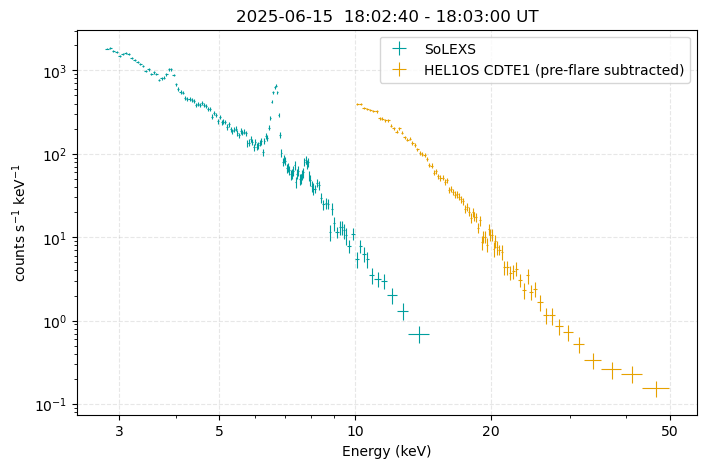

In [6]:
import xspec as xs

SHOW = max((r for r in rows if r['slx_file'] and r['hls_file']), key=lambda r: r['hls_counts'])   # or: SHOW = rows[10]

xs.Xset.chatter = 0
xs.AllData.clear()
cwd = os.getcwd()
os.chdir(OUT)                       # the HEL1OS files name their response and background without a path
try:
    xs.AllData(f'1:1 {SHOW["slx_file"]} 2:2 {SHOW["hls_file"]}')
    xs.AllData.ignore('bad')
    xs.Plot.device = '/null'
    xs.Plot.xAxis = 'keV'
    xs.Plot('data')
    plot = {i: (xs.Plot.x(i), xs.Plot.xErr(i), xs.Plot.y(i), xs.Plot.yErr(i)) for i in (1, 2)}
    for i, name in ((1, 'SoLEXS'), (2, 'HEL1OS')):
        s = xs.AllData(i)
        print(f'{name}: {s.fileName}  {len(s.noticed)} groups, net rate {s.rate[0]:.1f} counts/s')
finally:
    os.chdir(cwd)

fig, ax = plt.subplots(figsize=(8, 5))
for i, name, col in ((1, 'SoLEXS', '#009e9e'), (2, f'HEL1OS {HLS_DETECTOR} (pre-flare subtracted)', '#e6a100')):
    x, dx, y, dy = (np.array(v) for v in plot[i])
    ax.errorbar(x, y, dy, dx, fmt='none', color=col, lw=0.8, label=name)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Energy (keV)')
ax.set_ylabel(r'counts s$^{-1}$ keV$^{-1}$')
ax.set_title(f'{DAY}  {SHOW["start"]} - {SHOW["stop"]} UT')
ax.set_xticks([3, 5, 10, 20, 50])
ax.xaxis.set_major_formatter(plt.ScalarFormatter())
ax.legend()
ax.grid(ls='--', alpha=0.3)
plt.show()